# LAB1 – Bài 2 (Trang 28): Khảo sát và tiền xử lý dữ liệu Bank marketing
**Sinh viên:** Đinh Văn Bình – **MSSV:** 6351071007

## Câu 3: Vẽ biểu đồ khảo sát sự liên quan giữa Độ tuổi (age), Tình trạng hôn nhân (marital) và thuộc tính quyết định – khả năng đăng ký gửi tiền có kỳ hạn (y)

*Ghi chú:* Câu 3 của phần hướng dẫn (Titanic) khảo sát `age`, `sex` với `survived`. Dữ liệu Bank marketing không có thuộc tính giới tính, nên thuộc tính nhân khẩu học tương ứng được chọn là **Tình trạng hôn nhân (marital)**; thuộc tính quyết định là **y** (Subscribe: yes/no).

In [1]:
print('Họ tên: Đinh Văn Bình - MSSV: 6351071007')

Họ tên: Đinh Văn Bình - MSSV: 6351071007


### Bước 1. Import thư viện và đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt

with open('bank-additional-full.csv') as f:
    df = pd.read_csv(f, sep=';')

# Chuyển thuộc tính quyết định y (yes/no) thành số 1/0 để tính tỷ lệ
df['subscribed'] = (df['y'] == 'yes').astype(int)
print('Kích thước dữ liệu (dòng, cột):', df.shape)
print(df['marital'].value_counts())

Kích thước dữ liệu (dòng, cột): (41188, 22)
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64


### Bước 2. Vẽ biểu đồ phân bố tuổi theo khả năng đăng ký, tách riêng theo tình trạng hôn nhân
- Màu xanh lá (`g`): có đăng ký (`yes`), màu vàng (`y`): không đăng ký (`no`).
- Bỏ 80 dòng có `marital = 'unknown'` (giá trị thiếu, đã thấy ở Câu 2).

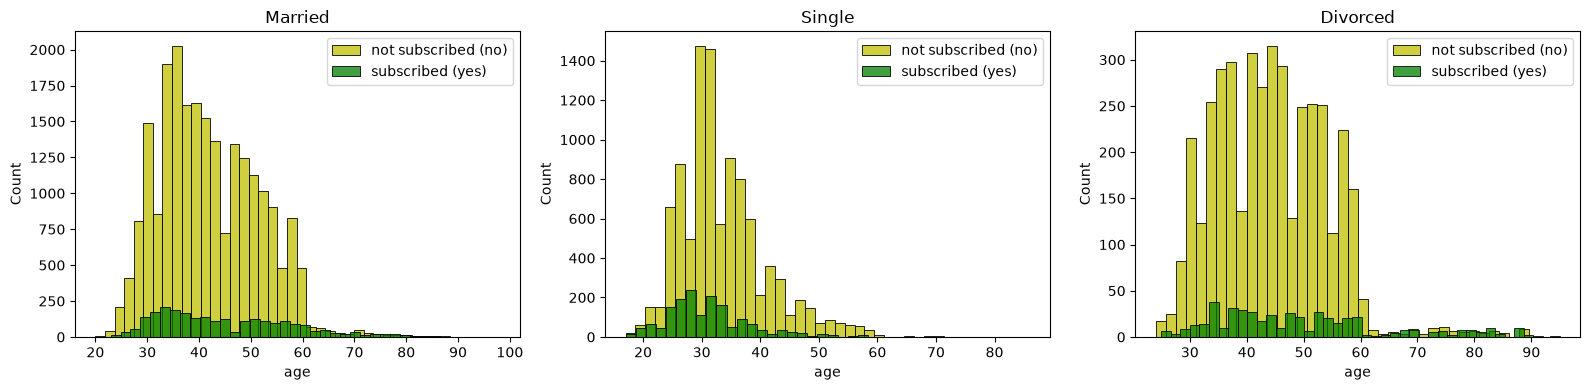

In [3]:
subscribed = 'subscribed (yes)'
not_subscribed = 'not subscribed (no)'
groups = ['married', 'single', 'divorced']
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))

for ax, g in zip(axes, groups):
    part = df[df['marital'] == g]
    sns.histplot(part[part['subscribed'] == 0].age, bins=40, label=not_subscribed, ax=ax, kde=False, color='y')
    sns.histplot(part[part['subscribed'] == 1].age, bins=40, label=subscribed, ax=ax, kde=False, color='g')
    ax.legend()
    ax.set_title(g.capitalize())
plt.tight_layout()

### Bước 3. Biểu đồ tỷ lệ đăng ký theo nhóm tuổi và tình trạng hôn nhân
Vì số khách đăng ký chỉ chiếm khoảng 11%, cột xanh ở Bước 2 rất thấp, khó so sánh. Biểu đồ dưới đây vẽ trực tiếp **tỷ lệ đăng ký (%)** của từng nhóm tuổi.

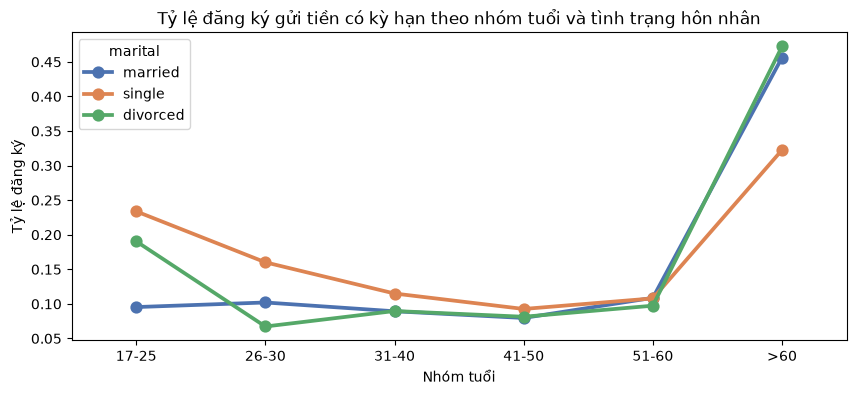

In [4]:
known = df[df['marital'] != 'unknown'].copy()
known['age_group'] = pd.cut(known['age'], bins=[16, 25, 30, 40, 50, 60, 98],
                            labels=['17-25', '26-30', '31-40', '41-50', '51-60', '>60'])
plt.figure(figsize=(10, 4))
ax = sns.pointplot(x='age_group', y='subscribed', hue='marital', data=known,
                   hue_order=groups, palette='deep', errorbar=None)
ax.set_xlabel('Nhóm tuổi')
ax.set_ylabel('Tỷ lệ đăng ký')
_ = ax.set_title('Tỷ lệ đăng ký gửi tiền có kỳ hạn theo nhóm tuổi và tình trạng hôn nhân')

### Bước 4. Bảng số liệu tỷ lệ đăng ký (minh họa cho nhận xét)

In [5]:
print('Tỷ lệ đăng ký theo tình trạng hôn nhân (%):')
print((known.groupby('marital')['subscribed'].mean() * 100).round(1))

rate = (known.groupby(['age_group', 'marital'], observed=True)['subscribed'].mean() * 100).round(1).unstack()
count = known.groupby(['age_group', 'marital'], observed=True)['subscribed'].size().unstack()
print('\nTỷ lệ đăng ký (%) theo nhóm tuổi và tình trạng hôn nhân:')
print(rate[groups])
print('\nSố khách hàng theo nhóm tuổi và tình trạng hôn nhân:')
print(count[groups])

print('\nTỷ lệ đăng ký (%) theo nhóm tuổi (tất cả):')
print((known.groupby('age_group', observed=True)['subscribed'].mean() * 100).round(1))

Tỷ lệ đăng ký theo tình trạng hôn nhân (%):
marital
divorced    10.3
married     10.2
single      14.0
Name: subscribed, dtype: float64

Tỷ lệ đăng ký (%) theo nhóm tuổi và tình trạng hôn nhân:
marital    married  single  divorced
age_group                           
17-25          9.5    23.4      19.0
26-30         10.2    16.0       6.7
31-40          8.9    11.5       9.0
41-50          8.0     9.3       8.1
51-60         10.9    10.8       9.7
>60           45.6    32.3      47.2

Số khách hàng theo nhóm tuổi và tình trạng hôn nhân:
marital    married  single  divorced
age_group                           
17-25          283    1360        21
26-30         2107    3391       208
31-40         9705    5139      1505
41-50         7383    1295      1548
51-60         4753     352      1150
>60            697      31       180

Tỷ lệ đăng ký (%) theo nhóm tuổi (tất cả):
age_group
17-25    21.0
26-30    13.5
31-40     9.7
41-50     8.2
51-60    10.7
>60      45.5
Name: subscribed, dtyp

### Nhận xét
- **Tỷ lệ đăng ký chung thấp** (khoảng 11%), nên ở biểu đồ phân bố, cột vàng (không đăng ký) luôn cao hơn cột xanh ở mọi độ tuổi và mọi nhóm hôn nhân.
- **Tình trạng hôn nhân:** khách **độc thân (single)** đăng ký nhiều nhất (**14.0%**), cao hơn người **đã kết hôn** (10.2%) và **ly hôn** (10.3%). Một phần là do nhóm độc thân tập trung ở độ tuổi trẻ.
- **Độ tuổi có ảnh hưởng rõ rệt, theo hình chữ U:**
  - Khách **trên 60 tuổi** có tỷ lệ đăng ký cao vượt trội (khoảng **32–47%**), cao nhất ở người ly hôn (47.2%) và đã kết hôn (45.6%). Đây là nhóm đã nghỉ hưu, có tiền nhàn rỗi và ưa kênh đầu tư an toàn.
  - Khách **trẻ dưới 25 tuổi** cũng đăng ký khá cao, nhất là người độc thân (23.4%), có thể là sinh viên.
  - Nhóm **31–50 tuổi** (đông khách nhất, hầu hết đã kết hôn) có tỷ lệ đăng ký thấp nhất, chỉ khoảng **8–11%**.
- Phần lớn khách hàng ở độ tuổi 30–50 và đã kết hôn, nên đây là vùng có nhiều khách **không đăng ký** nhất trên biểu đồ.
- **Kết luận:** `age` là thuộc tính quan trọng để dự đoán khả năng đăng ký (khách lớn tuổi và rất trẻ dễ đăng ký hơn). `marital` có ảnh hưởng nhưng yếu hơn, và phần lớn ảnh hưởng đó đến từ việc nhóm độc thân trẻ tuổi hơn.